# State Unemployment Forecasting

- Data: 50 states and DC, 2014–2024.
- Goal: predict unemployment rates three reference months ahead.
- Model: ordinary linear regression (OLS).


## 1. Check the environment

- Use the `data1030` kernel.
- Check Python and package versions.


In [1]:
import sys
import json
import urllib.request
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

assert Path(sys.prefix).name == "data1030", "请选择 Python (data1030) kernel"
ROOT = Path.cwd()
assert (ROOT / "unemployment_linear_regression.ipynb").exists(), "请在 Notebook 所在目录运行"
print("Environment:", Path(sys.prefix).name)
print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "pandas:", pd.__version__, "sklearn:", sklearn.__version__)


Environment: data1030
Python: 3.14.6
numpy: 2.4.6 pandas: 3.0.3 sklearn: 1.9.0


## 2. Collect BLS data

- Download seasonally adjusted monthly unemployment rates.
- Use six API requests; save and reuse the raw JSON files.
- Skip annual averages (`M13`).
- Check for missing months, duplicates, and invalid rates.
- Sources: [API format](https://www.bls.gov/developers/api_signature.htm), [API limits](https://www.bls.gov/developers/api_FAQs.htm), [definitions](https://www.bls.gov/help/def/la.htm), [state codes](https://download.bls.gov/pub/time.series/la/la.area).


In [2]:
API = "https://api.bls.gov/publicAPI/v1/timeseries/data/"
state_codes = "01 02 04 05 06 08 09 10 11 12 13 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 44 45 46 47 48 49 50 51 53 54 55 56".split()
series_to_state = {f"LASST{fips}0000000000003": fips for fips in state_codes}
assert len(series_to_state) == 51
assert "LASST440000000000003" in series_to_state
series_ids = list(series_to_state)
requests = [{"seriesid": series_ids[i:i+25], "startyear": str(start), "endyear": str(end)}
            for start, end in [(2014, 2023), (2024, 2024)]
            for i in range(0, len(series_ids), 25)]
print("POST", API)
print("Example payload:", json.dumps({"seriesid": ["LASST440000000000003"],
                                     "startyear": "2014", "endyear": "2023"}))

raw_dir = ROOT / "raw"
raw_dir.mkdir(exist_ok=True)
rows = []
for number, payload in enumerate(requests, 1):
    path = raw_dir / f"batch_{number:02d}.json"
    if path.exists():
        saved = json.loads(path.read_text())
        assert saved["request"] == payload, "缓存参数不符，请检查 raw 目录"
        response = saved["response"]
        print(f"Batch {number}/{len(requests)}: local API response")
    else:
        request = urllib.request.Request(API, data=json.dumps(payload).encode(),
                                         headers={"Content-Type": "application/json"}, method="POST")
        with urllib.request.urlopen(request, timeout=45) as connection:
            response = json.load(connection)
        assert response.get("status") == "REQUEST_SUCCEEDED", response.get("message")
        saved = {"retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                 "request": payload, "response": response}
        path.write_text(json.dumps(saved, ensure_ascii=False) + "\n")
        print(f"Batch {number}/{len(requests)}: collected via API")
    assert response.get("status") == "REQUEST_SUCCEEDED", response.get("message")
    returned = response["Results"]["series"]
    returned_ids = [item["seriesID"] for item in returned]
    assert set(returned_ids) == set(payload["seriesid"]) and len(returned_ids) == len(payload["seriesid"])
    for item in returned:
        for point in item["data"]:
            if point["period"] == "M13":
                continue
            assert point["period"] in {f"M{month:02d}" for month in range(1, 13)}
            rows.append({"state_code": series_to_state[item["seriesID"]],
                         "month": f'{point["year"]}-{point["period"][1:]}',
                         "unemployment_rate": float(point["value"].replace(",", ""))})
data = pd.DataFrame(rows).sort_values(["state_code", "month"]).reset_index(drop=True)
assert not data.duplicated(["state_code", "month"]).any()
assert data.groupby("state_code").size().eq(132).all() and len(data) == 51 * 132
assert data.month.between("2014-01", "2024-12").all()
assert data.unemployment_rate.between(0, 100).all() and np.isfinite(data.unemployment_rate).all()
data.to_csv(ROOT / "state_month_unemployment.csv", index=False)
print("Shape:", data.shape, "| range:", data.month.min(), "to", data.month.max())
display(data[data.state_code == "44"].head())


POST https://api.bls.gov/publicAPI/v1/timeseries/data/
Example payload: {"seriesid": ["LASST440000000000003"], "startyear": "2014", "endyear": "2023"}


Batch 1/6: collected via API


Batch 2/6: collected via API
Batch 3/6: collected via API


Batch 4/6: collected via API


Batch 5/6: collected via API
Batch 6/6: collected via API


Shape: (6732, 3) | range: 2014-01 to 2024-12


,state_code,month,unemployment_rate
5148,44,2014-01,8.9
5149,44,2014-02,8.7
5150,44,2014-03,8.5
5151,44,2014-04,8.2
5152,44,2014-05,8.0


## 3. Create features and the target

- One row = one state and one reference month.
- Inputs: current rate, 1/3/6/12-month lags, and state identity.
- Target: the same state's rate three months later.
- Align monthly dates within each state before shifting values.
- Rates are percentages: `4.5` means 4.5%.
- Dates and the future target are not model inputs.


In [3]:
def make_table(panel):
    assert not panel.duplicated(["state_code", "month"]).any()
    calendar = pd.period_range(panel.month.min(), panel.month.max(), freq="M")
    pieces = []
    for state, group in panel.groupby("state_code", sort=True):
        group = group.copy()
        group["month"] = pd.PeriodIndex(group.month, freq="M")
        history = group.set_index("month")[["unemployment_rate"]].reindex(calendar)
        for lag in (1, 3, 6, 12):
            history[f"lag_{lag}m"] = history.unemployment_rate.shift(lag)
        history["target_unemployment_rate"] = history.unemployment_rate.shift(-3)
        history["target_month"] = (calendar + 3).astype(str)
        history["state_code"] = state
        history["month"] = calendar.astype(str)
        pieces.append(history.reset_index(drop=True))
    return pd.concat(pieces, ignore_index=True)


In [4]:
numeric_features = ["unemployment_rate", "lag_1m", "lag_3m", "lag_6m", "lag_12m"]
target = "target_unemployment_rate"
table = make_table(data)
table = table[(table.month >= "2015-01")].dropna(subset=numeric_features + [target]).copy()
assert np.isfinite(table[numeric_features + [target]].to_numpy()).all()
table.to_csv(ROOT / "model_data.csv", index=False)
print("Complete labeled rows:", len(table))
display(table[table.state_code == "44"].head())


Complete labeled rows: 5967


,unemployment_rate,lag_1m,lag_3m,lag_6m,lag_12m,target_unemployment_rate,target_month,state_code,month
5160,6.5,6.7,7.1,7.6,8.9,6.3,2015-04,44,2015-01
5161,6.4,6.5,6.9,7.5,8.7,6.2,2015-05,44,2015-02
5162,6.4,6.4,6.7,7.3,8.5,6.0,2015-06,44,2015-03
5163,6.3,6.4,6.5,7.1,8.2,5.9,2015-07,44,2015-04
5164,6.2,6.3,6.4,6.9,8.0,5.8,2015-08,44,2015-05


## 4. Split the data and fit the model

- Train: January 2015–September 2021.
- Test: January 2022–September 2024.
- Exclude October–December 2021: their targets fall in 2022.
- Split by time; do not shuffle rows.
- One-hot encode states and align test columns with training columns.
- Fit one `LinearRegression` model without tuning.


In [5]:
train = table[(table.month < "2022-01") & (table.target_month < "2022-01")].copy()
test = table[table.month >= "2022-01"].copy()
assert len(train) > 0 and len(test) > 0
assert train.target_month.max() < test.month.min()
assert set(test.state_code) <= set(train.state_code)

X_train = pd.get_dummies(train[numeric_features + ["state_code"]],
                         columns=["state_code"], drop_first=True, dtype=float)
X_test = pd.get_dummies(test[numeric_features + ["state_code"]],
                        columns=["state_code"], drop_first=True, dtype=float).reindex(
                            columns=X_train.columns, fill_value=0)
model = LinearRegression()
model.fit(X_train, train[target])
predicted = model.predict(X_test)
print("Model:", type(model).__name__, "| encoded predictors:", X_train.shape[1])
print("Train:", len(train), "rows,", train.month.min(), "to", train.month.max())
print("Test: ", len(test), "rows,", test.month.min(), "to", test.month.max())


Model: LinearRegression | encoded predictors: 55
Train: 4131 rows, 2015-01 to 2021-09
Test:  1683 rows, 2022-01 to 2024-09


## 5. Evaluate predictions

- Report MAE, RMSE, and R² across test state-months.
- MAE and RMSE use percentage points; lower is better.
- Negative R² means more squared error than predicting the test mean.


In [6]:
metrics = {"MAE_percentage_points": float(mean_absolute_error(test[target], predicted)),
           "RMSE_percentage_points": float(np.sqrt(mean_squared_error(test[target], predicted))),
           "R2": float(r2_score(test[target], predicted))}
predictions = test[["state_code", "month", "target_month", "unemployment_rate", target]].copy()
predictions["linear_regression_prediction"] = predicted
predictions.to_csv(ROOT / "test_predictions.csv", index=False)
record = {"environment": Path(sys.prefix).name, "python": sys.version.split()[0],
          "packages": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
          "model": "sklearn.linear_model.LinearRegression", "train_rows": len(train),
          "test_rows": len(test), "metrics": metrics,
          "scope": "Local exploratory evaluation using currently revised historical BLS data."}
(ROOT / "metrics.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n")
display(pd.Series(metrics, name="Linear Regression").to_frame())
display(predictions[predictions.state_code == "44"].head(8))


,Linear Regression
MAE_percentage_points,0.772024
RMSE_percentage_points,0.854262
R2,-0.163822


,state_code,month,target_month,unemployment_rate,target_unemployment_rate,linear_regression_prediction
5244,44,2022-01,2022-04,3.5,3.1,4.423374
5245,44,2022-02,2022-05,3.3,3.1,4.353711
5246,44,2022-03,2022-06,3.2,3.2,4.331463
5247,44,2022-04,2022-07,3.1,3.3,4.284782
5248,44,2022-05,2022-08,3.1,3.4,4.296905
5249,44,2022-06,2022-09,3.2,3.3,4.344886
5250,44,2022-07,2022-10,3.3,3.2,4.408599
5251,44,2022-08,2022-11,3.4,3.1,4.480724


## 6. Explore the data

- Figure 1: unemployment trends across states.
- Figure 2: current rates versus rates three months later.
- Figure 3: future-rate distributions across time periods.
- These figures include the already-viewed test period.

- Figure 4: Rhode Island training-period autocorrelation (Lecture 10).


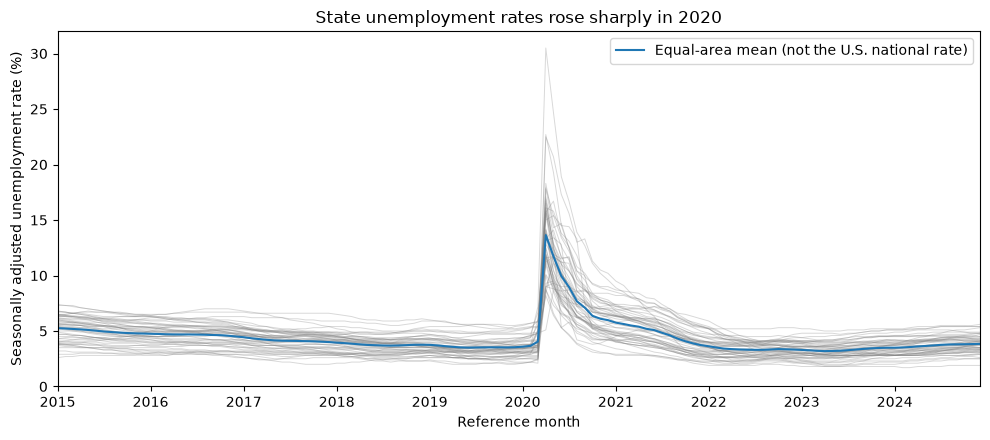

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt

trend = data[data["month"] >= "2015-01"].pivot(
    index="month", columns="state_code", values="unemployment_rate"
)
plot_months = pd.to_datetime(trend.index)

plt.figure(figsize=(10, 4.5))
plt.plot(plot_months, trend, color="gray", alpha=0.3, linewidth=0.7)
plt.plot(plot_months, trend.mean(axis=1), color="tab:blue",
         label="Equal-area mean (not the U.S. national rate)")
plt.title("State unemployment rates rose sharply in 2020")
plt.xlabel("Reference month")
plt.ylabel("Seasonally adjusted unemployment rate (%)")
plt.xlim(plot_months.min(), plot_months.max())
plt.ylim(0, 32)
plt.legend()
plt.tight_layout()
plt.show()


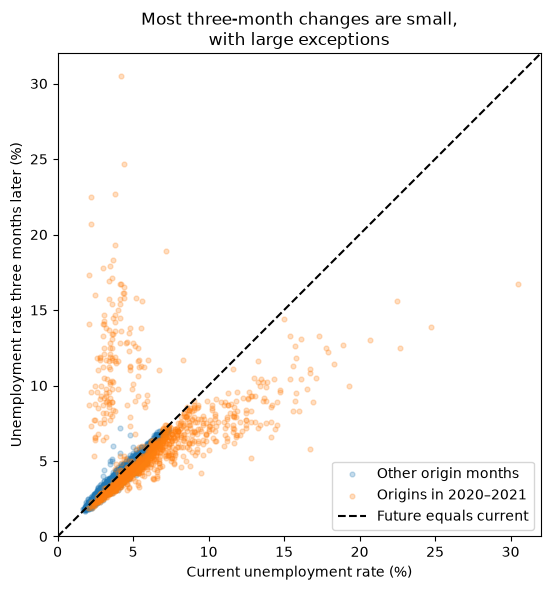

In [8]:
pandemic_months = table["month"].between("2020-01", "2021-12")

plt.figure(figsize=(6.5, 6))
plt.scatter(table.loc[~pandemic_months, "unemployment_rate"],
            table.loc[~pandemic_months, "target_unemployment_rate"],
            s=12, alpha=0.25, color="tab:blue", label="Other origin months")
plt.scatter(table.loc[pandemic_months, "unemployment_rate"],
            table.loc[pandemic_months, "target_unemployment_rate"],
            s=12, alpha=0.25, color="tab:orange", label="Origins in 2020–2021")
plt.plot([0, 32], [0, 32], "k--", label="Future equals current")
plt.title("Most three-month changes are small,\nwith large exceptions")
plt.xlabel("Current unemployment rate (%)")
plt.ylabel("Unemployment rate three months later (%)")
plt.axis("scaled")
plt.xlim(0, 32)
plt.ylim(0, 32)
plt.legend()
plt.tight_layout()
plt.show()


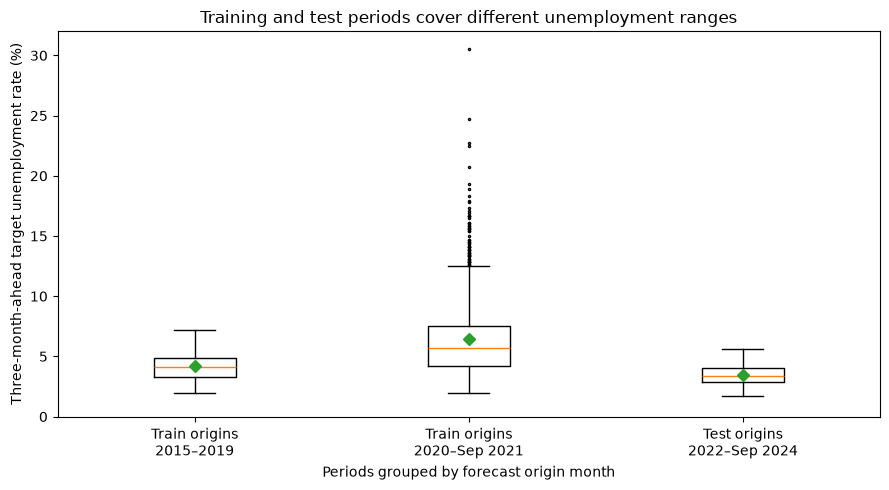

In [9]:
train_before_2020 = train.loc[train["month"] < "2020-01", "target_unemployment_rate"]
train_from_2020 = train.loc[train["month"] >= "2020-01", "target_unemployment_rate"]
test_rates = test["target_unemployment_rate"]

plt.figure(figsize=(9, 5))
plt.boxplot([train_before_2020, train_from_2020, test_rates],
            tick_labels=["Train origins\n2015–2019", "Train origins\n2020–Sep 2021",
                         "Test origins\n2022–Sep 2024"],
            showmeans=True, meanprops={"marker": "D"},
            flierprops={"marker": ".", "markersize": 3})
plt.title("Training and test periods cover different unemployment ranges")
plt.xlabel("Periods grouped by forecast origin month")
plt.ylabel("Three-month-ahead target unemployment rate (%)")
plt.ylim(0, 32)
plt.tight_layout()
plt.show()


### Autocorrelation (Lecture 10)

- Compare a time series with delayed copies of itself.
- Use Rhode Island training origins only: January 2015–September 2021.
- Each lag is one month; this example does not represent every state.
- This checks persistence, not forecast accuracy or optimal lag selection.

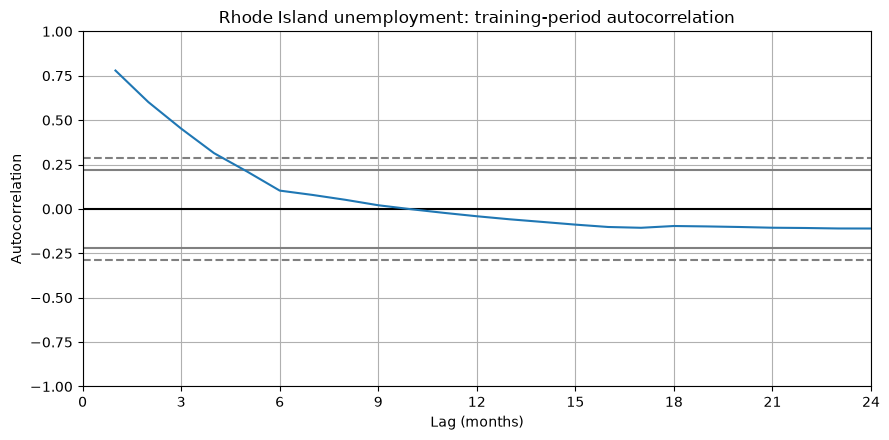

State: Rhode Island | months: 81
Reference months: 2015-01 to 2021-09


In [10]:
ri_train = train.loc[train["state_code"] == "44"].sort_values("month")
ri_train_rates = ri_train.set_index("month")["unemployment_rate"]

plt.figure(figsize=(9, 4.5))
pd.plotting.autocorrelation_plot(ri_train_rates)
plt.xlim(0, 24)
plt.xticks(range(0, 25, 3))
plt.xlabel("Lag (months)")
plt.ylabel("Autocorrelation")
plt.title("Rhode Island unemployment: training-period autocorrelation")
plt.tight_layout()
plt.show()

print("State: Rhode Island | months:", len(ri_train_rates))
print("Reference months:", ri_train_rates.index.min(), "to", ri_train_rates.index.max())

## Limitations

- Historical BLS values are revised; original release versions were not reconstructed.
- Month `t` is usually published in the following month; the target is reference month `t+3`.
- The test period has already been viewed. These are exploratory, retrospective results.
- Sources: [BLS methods and revisions](https://www.bls.gov/news.release/laus.tn.htm), [seasonal adjustment](https://www.bls.gov/lau/lauseas.htm).
- Data: BLS LAUS. Code prepared with Codex assistance.
